In [1]:
import json
import numpy as np

In [2]:
data = np.load('../results/energy_gap/160m/final.npz')
with open('../results/energy_gap/160m/final_meta.json') as f:
    meta = json.load(f)

attn_hist     = data['attn_hist']      # (n_layers, n_heads, n_bins)  int64
attn_overflow = data['attn_overflow']  # (n_layers, n_heads)          int64
lm_hist       = data['lm_hist']        # (n_bins,)                    int64
lm_overflow   = data['lm_overflow']    # scalar                       int64
bin_edges     = data['bin_edges']      # (n_bins+1,)                  float64

bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
bin_width   = bin_edges[1] - bin_edges[0]

n_layers, n_heads, n_bins = attn_hist.shape
gap_max = float(bin_edges[-1])

# Normalize histograms to probability densities
attn_counts = attn_hist.sum(axis=-1, keepdims=True) + attn_overflow[..., None]  # (n_layers, n_heads, 1)
attn_pdf    = attn_hist / (attn_counts * bin_width)  # (n_layers, n_heads, n_bins)

lm_counts = lm_hist.sum() + int(lm_overflow)
lm_pdf    = lm_hist / (lm_counts * bin_width)  # (n_bins,)

print(f"Model   : {meta['model']}  revision={meta['revision']}")
print(f"Tokens  : {meta['n_eval_tokens']:,}")
print(f"Bins    : {n_bins}  in [0, {gap_max}]  (width={bin_width:.4f})")
print(f"Shape   : attn_hist {attn_hist.shape},  lm_hist {lm_hist.shape}")
print(f"Overflow: attn {100*meta['attn_overflow_frac']:.3f}%,  lm {100*meta['lm_overflow_frac']:.3f}%")

# Per-head summary statistics (mean and std of the distribution)
attn_mean = (attn_hist * bin_centers).sum(axis=-1) / attn_hist.sum(axis=-1)  # (n_layers, n_heads)
lm_mean   = (lm_hist * bin_centers).sum() / lm_hist.sum()
print(f"\nLM head gap mean : {lm_mean:.4f}")
print(f"Attn gap mean    : layer-averaged = {attn_mean.mean():.4f}")
print(f"  per layer (mean over heads): {attn_mean.mean(axis=1).round(3)}")

Model   : EleutherAI/pythia-160m  revision=None
Tokens  : 2,000,000
Bins    : 1000  in [0, 5.0]  (width=0.0050)
Shape   : attn_hist (12, 12, 1000),  lm_hist (1000,)
Overflow: attn 0.003%,  lm 0.000%

LM head gap mean : 0.0286
Attn gap mean    : layer-averaged = 0.4111
  per layer (mean over heads): [0.18  0.198 0.373 0.409 0.439 0.54  0.555 0.465 0.448 0.445 0.436 0.444]


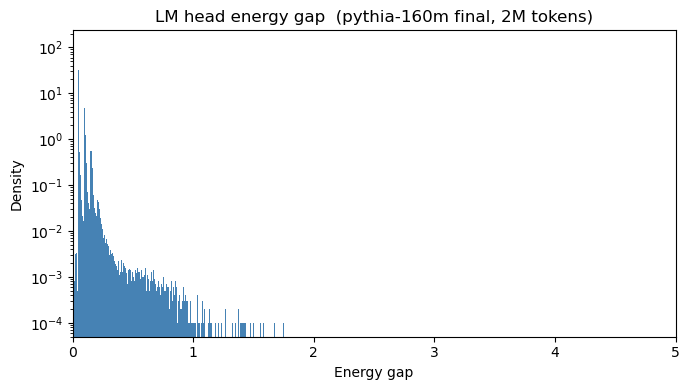

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(bin_centers, lm_pdf, width=bin_width, color='steelblue', edgecolor='none')
ax.set_xlabel('Energy gap')
ax.set_ylabel('Density')
ax.set_title(f'LM head energy gap  (pythia-160m final, {meta["n_eval_tokens"]//1_000_000}M tokens)')
ax.set_xlim(0, gap_max)
ax.set_yscale('log')
plt.tight_layout()

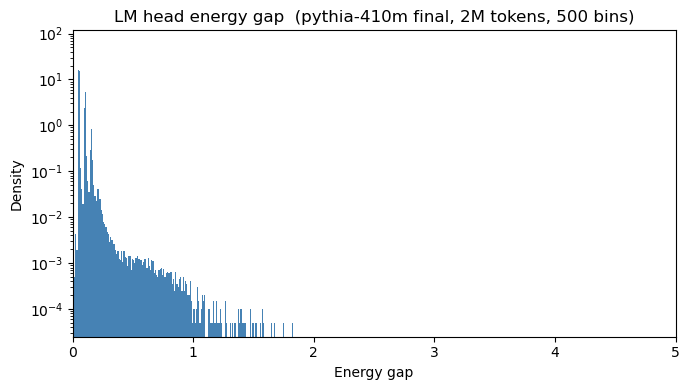

In [4]:
lm_hist_500   = lm_hist.reshape(500, 2).sum(axis=-1)
bin_edges_500 = bin_edges[::2]
bin_centers_500 = 0.5 * (bin_edges_500[:-1] + bin_edges_500[1:])
bin_width_500   = bin_edges_500[1] - bin_edges_500[0]
lm_pdf_500 = lm_hist_500 / (lm_counts * bin_width_500)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(bin_centers_500, lm_pdf_500, width=bin_width_500, color='steelblue', edgecolor='none')
ax.set_xlabel('Energy gap')
ax.set_ylabel('Density')
ax.set_title(f'LM head energy gap  (pythia-410m final, {meta["n_eval_tokens"]//1_000_000}M tokens, 500 bins)')
ax.set_xlim(0, gap_max)
#ax.set_xscale('log')
ax.set_yscale('log')
plt.tight_layout()

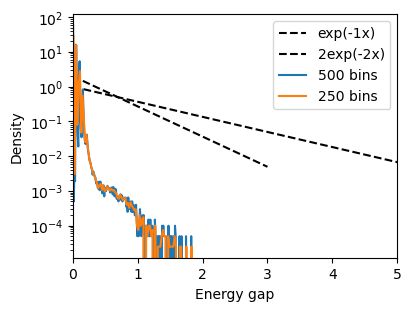

In [5]:
bin_centers_250 = 0.5 * (bin_edges[::4][:-1] + bin_edges[::4][1:])
lm_hist_250 = lm_hist.reshape(250, 4).sum(axis=-1)
lm_pdf_250 = lm_hist_250 / (lm_counts * (bin_edges[4] - bin_edges[0]))
plt.figure(figsize=(4, 3), constrained_layout=True)
#plt.plot(bin_centers, lm_pdf, label='1000 bins')
plt.plot([0, 5], [1, 1*np.exp(-1*5)], 'k--',label='exp(-1x)')
plt.plot([0, 3], [2, 2*np.exp(-2*3)], 'k--',label='2exp(-2x)')
#plt.plot([0, 2], [3, 3*np.exp(-3*2)], 'k--',label='3exp(-3x)')
plt.plot(bin_centers_500, lm_pdf_500, label='500 bins')
plt.plot(bin_centers_250, lm_pdf_250, label='250 bins')
plt.xlabel('Energy gap')
plt.ylabel('Density')
#plt.title(f'LM head energy gap  (pythia-410m final, {meta["n_eval_tokens"]//1_000_000}M tokens)')
plt.xlim(0, 5)
plt.yscale('log')
#plt.xscale('log')
plt.legend()

If the underlying distribution is smooth near 0, then, as we reduce the bin, because it has larger PDF, it should be less affected by the binning, as there are more samples in them. But we observed the opposite. Does this suggest that the distribtion is not very smooth near 0?

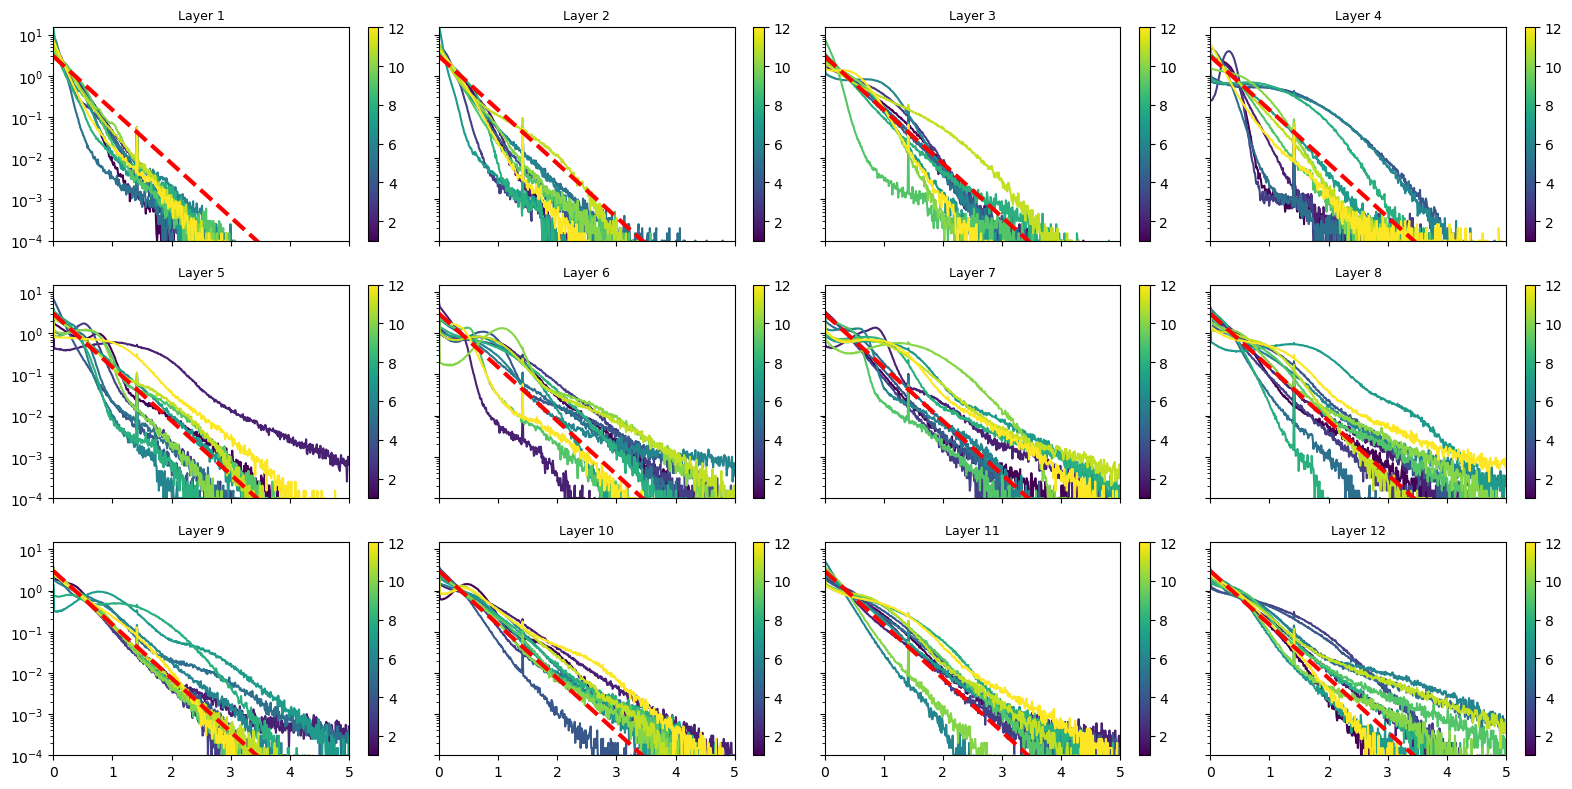

In [6]:
import matplotlib.colors as mcolors

attn_hist_500 = attn_hist.reshape(n_layers, n_heads, 500, 2).sum(axis=-1)
attn_pdf_500  = attn_hist_500 / (attn_counts * bin_width_500)  # (n_layers, n_heads, 500)

cmap = plt.get_cmap('viridis')
norm = mcolors.Normalize(vmin=1, vmax=n_heads)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig, axs = plt.subplots(3, n_layers // 3, figsize=(16, 8), sharex=True, sharey=True)
for layer, ax in enumerate(axs.flatten()):
    for head in range(n_heads):
        ax.plot(bin_centers_500, attn_pdf_500[layer, head], color=cmap(head / (n_heads - 1)))
    ax.plot([0, 4], [3, 3*np.exp(-4*3)], 'r--', linewidth=3)
    ax.set_title(f'Layer {layer + 1}', fontsize=9)
    ax.set_xlim(0, gap_max)
    ax.set_ylim(1e-4, None)
    ax.set_yscale('log')
    fig.colorbar(sm, ax=ax)
plt.tight_layout()

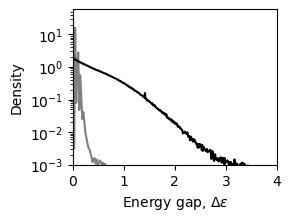

In [7]:
plt.figure(figsize=(2.8, 2.1), constrained_layout=True)
plt.plot(bin_centers_250, lm_pdf_250, 'grey')
plt.plot(bin_centers_500, attn_pdf_500[10, 3], 'k')
plt.yscale('log')
plt.xlim(0,4)
plt.ylim(1e-3,None)
plt.xlabel(r'Energy gap, $\Delta \epsilon$')
plt.ylabel(r'Density')
plt.savefig('../figures/energy_gap_160m.pdf')